# Conlang Translator
<a id="title"></a>

[Project Repo](https://github.com/Ethereal-Mining-Company/conlang-translator) \
Christopher Doupis \
December 6, 2026

<div class="alert alert-info" style="color: black;">
    
### AI USE DISCLAIMER & ACADEMIC INTEGRITY COMPLIANCE
In compliance with the [**National University Student Guidelines for Generative AI**](https://resources.nu.edu/ai/ai-guidelines), this project discloses the following tool usage:

* **Conceptual Framing & Brainstorming (AI-Informed):** **Google Gemini** was utilized as a supplemental learning resource to clarify core mathematical and analytical concepts across the assignment questions. 
* **Technical Execution & Boilerplate Generation (AI-Assisted):** **Google Gemini** was used to generate initial code structures and programming boilerplates. These templates were subsequently modified, debugged, and tailored to meet the specific requirements of each question.
* **Human Oversight, Validation Loops & Refinement (Author-Owned):** The author maintained complete conceptual control, process oversight, and ownership of the entire homework scope. All AI-assisted templates, code logic, and conceptual outputs were systematically reviewed and validated by the author to ensure academic accuracy and integrity.
* **Disclosure Statement (AI-Generated):** **Google Gemini** was utilized to structure and audit this text format to fulfill all institutional reporting standards.
</div>

### REFERENCES
#### Peer Reviewed and Scientific References
* **[Breiman, L.](/references/breiman_2001.pdf)** (2001). Random Forests. *Machine Learning*, 45(1), 5–32. https://doi.org
* **[Lample, G., Ballesteros, M., Subramanian, S., Kawakami, K., & Dyer, C.](/references/lample_2016.pdf)** (2016, June 1). Neural architectures for named entity recognition. *ACLWeb; Association for Computational Linguistics*. https://doi.org/10.18653/v1/N16-1030
* **[Linguistic Data Consortium, & Kulick, A. B. J. M. C. W. S.](https://doi.org/https://doi.org/10.35111/m5b6-4m82
)** (n.d.). *English web treebank*. Linguistic Data Consortium. https://doi.org/https://doi.org/10.35111/m5b6-4m82
* **[Ma, X., & Hovy, E.](/references/ma_2016.pdf)** (2016, August 1). End-to-end sequence labeling via bi-directional LSTM-CNNs-CRF. *ACLWeb; Association for Computational Linguistics*. https://doi.org/10.18653/v1/P16-1101
* **[Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., Killeen, T., Lin, Z., Gimelshein, N., Antiga, L., Desmaison, A., Köpf, A., Yang, E., DeVito, Z., Raison, M., Tejani, A., Chilamkurthy, S., Steiner, B., Fang, L., … Chintala, S.](/references/paszke_2019.pdf)** (2019). PyTorch: An imperative style, high-performance deep learning library. *arXiv.org*. https://arxiv.org/abs/1912.01703
* **[Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É.](https://jmlr.org/papers/v12/pedregosa11a.html)** (2011). Scikit-learn: Machine learning in python. *Journal of Machine Learning Research*, 12(85), 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

#### Generative AI & Software Tools
* **[Google.](https://google.com)** (2026). *Gemini* [Large language model]. https://google.com


In [23]:
import json
from collections import Counter
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from src.engine import DynamicTranslator
from src.features import load_dataset_splits
from src.models import diagnose_all_models, get_tagger, run_experiments
from src.utils import export_comparison_png, export_eda_png, export_epochs_png, load_config, resolve_path

cfg = load_config()
translator = DynamicTranslator(cfg["paths"]["languages_dir"], cfg["paths"]["english_rules"])

print("Active Languages:", translator.available_languages())
print("Default Production Model:", cfg["translator"]["active_model"])

Active Languages: ['english', 'aelorian', 'low_nerakan', 'vaelorian']
Default Production Model: bilstm_crf


In [19]:
train_s, dev_s, test_s, source_tag = load_dataset_splits(cfg)

eda_df = pd.DataFrame([
    {"Split": "Train", "Sentences": len(train_s), "Tokens": sum(len(s) for s in train_s)},
    {"Split": "Dev (Validation)", "Sentences": len(dev_s), "Tokens": sum(len(s) for s in dev_s)},
    {"Split": "Test (Held-Out)", "Sentences": len(test_s), "Tokens": sum(len(s) for s in test_s)},
])
display(eda_df)

tag_counts = Counter(tok["label"] for sent in train_s for tok in sent)
top_tags_df = pd.DataFrame(tag_counts.most_common(15), columns=["Target Label", "Token Count"])

title_eda = f"Top 15 Morphological & POS Target Classes ({source_tag})"
export_eda_png(top_tags_df, "Target Label", "Token Count", title_eda, cfg["paths"]["figures"])

fig_eda = px.bar(
    top_tags_df,
    x="Target Label",
    y="Token Count",
    title=title_eda,
    text_auto=True,
    color="Token Count",
    color_continuous_scale="Viridis",
)
fig_eda.update_layout(xaxis_tickangle=-35, showlegend=False)
fig_eda.show()

,Split,Sentences,Tokens
0,Train,12544,204578
1,Dev (Validation),2001,25148
2,Test (Held-Out),2077,25094


=== ALL LOGGED EXPERIMENT RUNS ===


,run_uuid,engine_type,run_name,promoted,tuned_params,mean_cv_accuracy,final_test_score,macro_f1,latency_ms
0,run_780dfdd1,random_forest,RF_Run_1,False,"{'n_estimators': 50, 'max_depth': 20}",0.616510,NaN,NaN,NaN
1,run_e3b46cd3,random_forest,RF_Run_2,False,"{'n_estimators': 50, 'max_depth': 40}",0.783005,NaN,NaN,NaN
2,run_178dcd7b,random_forest,RF_Run_3,False,"{'n_estimators': 50, 'max_depth': None}",0.928662,NaN,NaN,NaN
3,run_5b1b2291,random_forest,RF_Run_4,False,"{'n_estimators': 200, 'max_depth': 20}",0.622634,NaN,NaN,NaN
4,run_963228ec,random_forest,RF_Run_5,False,"{'n_estimators': 200, 'max_depth': 40}",0.789606,NaN,NaN,NaN
5,run_23bc0b84,random_forest,RF_Run_6,True,"{'n_estimators': 200, 'max_depth': None}",0.930491,0.929266,0.870476,0.1579
6,run_2db728ef,random_forest,RF_Run_1,False,"{'n_estimators': 50, 'max_depth': 20}",0.616510,NaN,NaN,NaN
7,run_3ea8af9b,random_forest,RF_Run_2,False,"{'n_estimators': 50, 'max_depth': 40}",0.783005,NaN,NaN,NaN
8,run_2844d6d3,random_forest,RF_Run_3,False,"{'n_estimators': 50, 'max_depth': None}",0.928662,NaN,NaN,NaN
9,run_9adb7005,random_forest,RF_Run_4,False,"{'n_estimators': 200, 'max_depth': 20}",0.622634,NaN,NaN,NaN


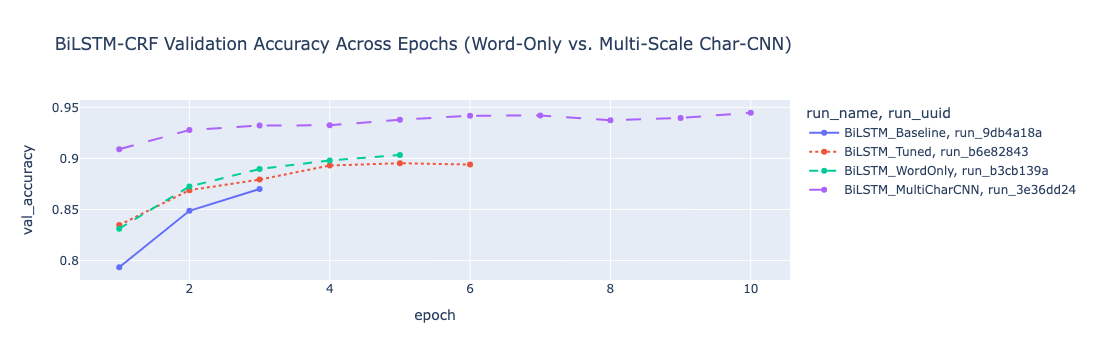

In [19]:
runs_df = pd.read_csv(resolve_path(cfg["paths"]["runs_csv"]))
epochs_df = pd.read_csv(resolve_path(cfg["paths"]["epochs_csv"]))

print("=== ALL LOGGED EXPERIMENT RUNS ===")
display(runs_df[["run_uuid", "engine_type", "run_name", "promoted", "tuned_params", "mean_cv_accuracy", "final_test_score", "macro_f1", "latency_ms"]])

bilstm_epochs = epochs_df[epochs_df["engine_type"] == "bilstm_crf"]
if not bilstm_epochs.empty:
    title_ep = "BiLSTM-CRF Validation Accuracy Across Epochs (Word-Only vs. Multi-Scale Char-CNN)"
    export_epochs_png(bilstm_epochs, title_ep, cfg["paths"]["figures"])
    fig_ep = px.line(
        bilstm_epochs,
        x="epoch",
        y="val_accuracy",
        color="run_name",
        line_dash="run_uuid",
        markers=True,
        title=title_ep,
    )
    fig_ep.show()

In [20]:
metrics_path = resolve_path(cfg["paths"]["artifacts_prod"]) / cfg["runtime"]["metrics_file"]
metrics_data = json.loads(metrics_path.read_text(encoding="utf-8"))

comp_rows = [
    {
        "Model": family,
        "Champion Run": info["best_run_name"],
        "Run UUID": info["best_run_uuid"],
        "Test Accuracy": info["best_test_metrics"]["test_accuracy"],
        "Macro F1": info["best_test_metrics"]["macro_f1"],
        "Latency (ms/sent)": info["best_test_metrics"]["latency_ms"],
    }
    for family, info in metrics_data.items()
]
comp_df = pd.DataFrame(comp_rows)
display(comp_df)

title_comp = "Production Model Head-to-Head Comparison"
export_comparison_png(comp_df, title_comp, cfg["paths"]["figures"])

fig_comp = go.Figure(data=[
    go.Bar(name="Test Accuracy", x=comp_df["Model"], y=comp_df["Test Accuracy"], text=comp_df["Test Accuracy"].map(lambda v: f"{v:.2%}"), textposition="auto"),
    go.Bar(name="Macro F1", x=comp_df["Model"], y=comp_df["Macro F1"], text=comp_df["Macro F1"].map(lambda v: f"{v:.4f}"), textposition="auto"),
])
fig_comp.update_layout(barmode="group", title=title_comp, yaxis_range=[0, 1.05])
fig_comp.show()

,Model,Champion Run,Run UUID,Test Accuracy,Macro F1,Latency (ms/sent)
0,Random Forest,RF_Tuned,run_b252c355,0.925998,0.861088,0.598994
1,BiLSTM-CRF,BiLSTM_MultiCharCNN,run_3e36dd24,0.949071,0.908096,1.301744
2,HistGradientBoosting,HGB_MaxSafe4096,run_5bdf7923,0.939428,0.893828,26.303586
3,MLP Neural Net,MLP_Compact,run_cdb1a9e8,0.940384,0.890322,0.091387


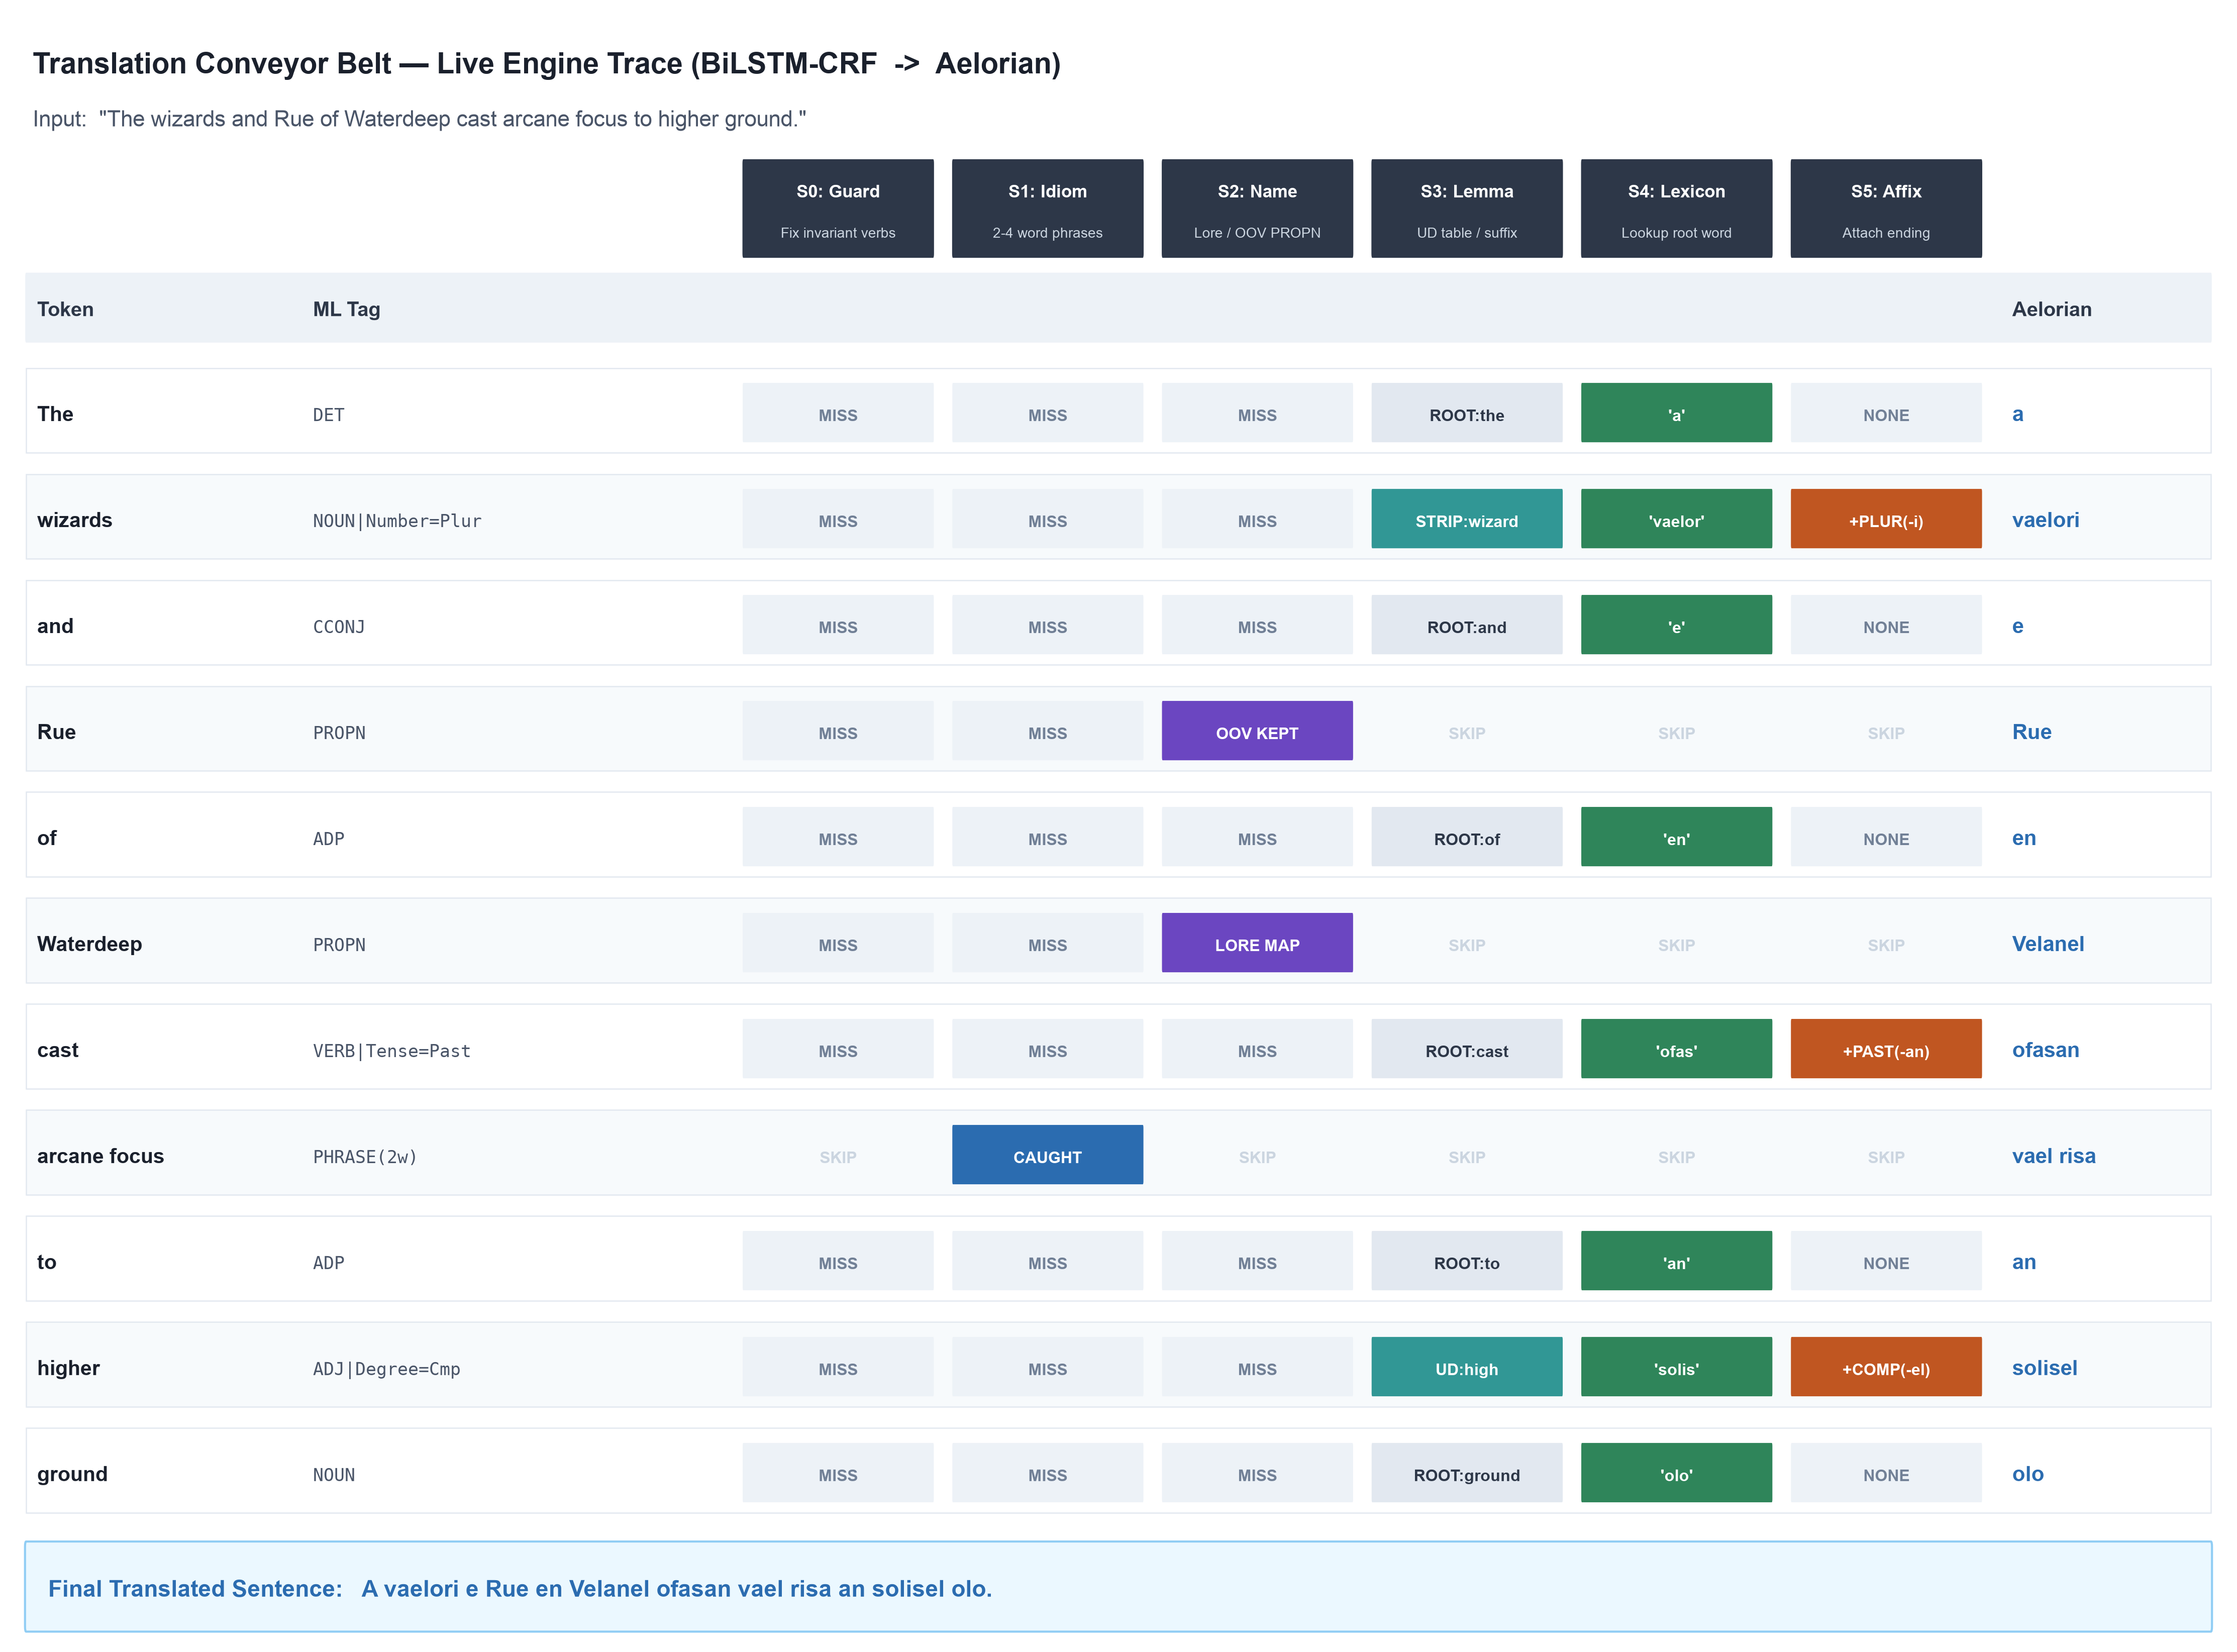

In [21]:
import importlib
import src.utils
import src.engine
import src.visualizations
from src.models import get_tagger
from src.utils import load_config

importlib.reload(src.utils)
importlib.reload(src.engine)
importlib.reload(src.visualizations)

cfg = load_config()
translator = src.engine.DynamicTranslator(cfg["paths"]["languages_dir"], cfg["paths"]["english_rules"])
tagger, model_name = get_tagger(cfg, model_key="bilstm_crf")

src.visualizations.export_conveyor_pptx_visual(
    sentence="The wizards and Rue of Waterdeep cast arcane focus to higher ground.",
    cfg=cfg,
    translator=translator,
    tagger=tagger,
    model_name=model_name,
    target_lang="aelorian",
)

In [28]:
import json
import pandas as pd
from src.utils import load_config, resolve_path

cfg = load_config()
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1200)

# 1. Print full hyperparameter grid & Dev vs. Test scores from experiment_runs.csv
runs_df = pd.read_csv(resolve_path(cfg["paths"].get("experiment_log", "logs/experiment_runs.csv")))
audit_cols = [
    c for c in ["model_family", "run_name", "tuned_params", "mean_cv_accuracy", "final_test_score", "macro_f1", "promoted", "run_uuid"]
    if c in runs_df.columns
]
print("=== HYPERPARAMETER SWEEP: DEV TUNING VS. HELD-OUT TEST ===")
display(runs_df[audit_cols])

# 2. Print exact winning hyperparameters stored in production model_metrics.json
metrics = json.loads(resolve_path("artifacts/production/model_metrics.json").read_text(encoding="utf-8"))
print("\n=== PROMOTED CHAMPION HYPERPARAMETERS (artifacts/production/model_metrics.json) ===")
for model_name, info in metrics.items():
    print(f"\n[{model_name}] (UUID: {str(info.get('run_uuid', ''))[:8]})")
    print(f"  Dev (Val) Score : {info.get('val_score')}")
    print(f"  Test Metrics    : {info.get('best_test_metrics')}")
    print(f"  Winning Params  : {info.get('best_params') or info.get('tuned_params')}")

=== HYPERPARAMETER SWEEP: DEV TUNING VS. HELD-OUT TEST ===


,run_name,tuned_params,mean_cv_accuracy,final_test_score,macro_f1,promoted,run_uuid
0,RF_Run_1,"{'n_estimators': 50, 'max_depth': 20}",0.616510,NaN,NaN,False,run_780dfdd1
1,RF_Run_2,"{'n_estimators': 50, 'max_depth': 40}",0.783005,NaN,NaN,False,run_e3b46cd3
2,RF_Run_3,"{'n_estimators': 50, 'max_depth': None}",0.928662,NaN,NaN,False,run_178dcd7b
3,RF_Run_4,"{'n_estimators': 200, 'max_depth': 20}",0.622634,NaN,NaN,False,run_5b1b2291
4,RF_Run_5,"{'n_estimators': 200, 'max_depth': 40}",0.789606,NaN,NaN,False,run_963228ec
5,RF_Run_6,"{'n_estimators': 200, 'max_depth': None}",0.930491,0.929266,0.870476,True,run_23bc0b84
6,RF_Run_1,"{'n_estimators': 50, 'max_depth': 20}",0.616510,NaN,NaN,False,run_2db728ef
7,RF_Run_2,"{'n_estimators': 50, 'max_depth': 40}",0.783005,NaN,NaN,False,run_3ea8af9b
8,RF_Run_3,"{'n_estimators': 50, 'max_depth': None}",0.928662,NaN,NaN,False,run_2844d6d3
9,RF_Run_4,"{'n_estimators': 200, 'max_depth': 20}",0.622634,NaN,NaN,False,run_9adb7005



=== PROMOTED CHAMPION HYPERPARAMETERS (artifacts/production/model_metrics.json) ===

[Random Forest] (UUID: )
  Dev (Val) Score : None
  Test Metrics    : {'test_accuracy': 0.925998246592811, 'macro_f1': 0.8610883023929987, 'latency_ms': 0.5989938613392106}
  Winning Params  : None

[BiLSTM-CRF] (UUID: )
  Dev (Val) Score : None
  Test Metrics    : {'test_accuracy': 0.9490714911931138, 'macro_f1': 0.9080964171976322, 'latency_ms': 1.3017439614880746}
  Winning Params  : None

[HistGradientBoosting] (UUID: )
  Dev (Val) Score : None
  Test Metrics    : {'test_accuracy': 0.9394277516537818, 'macro_f1': 0.893827961453816, 'latency_ms': 26.30358604140549}
  Winning Params  : None

[MLP Neural Net] (UUID: )
  Dev (Val) Score : None
  Test Metrics    : {'test_accuracy': 0.9403841555750379, 'macro_f1': 0.8903219297248453, 'latency_ms': 0.09138687577889583}
  Winning Params  : None


In [32]:
import joblib
import pandas as pd
import torch
from src.features import extract_token_features
from src.utils import load_config, resolve_path

cfg = load_config()
raw_words = ["The", "wizards", "and", "Rue", "of", "Waterdeep", "cast", "arcane", "focus", "to", "higher", "ground", "."]
sample_tokens = [{"word": w} for w in raw_words]

print("=" * 80)
print("1. RANDOM FOREST: ENGINEERED LINGUISTIC FEATURES (Token: 'wizards' & 'Rue')")
print("=" * 80)

fcfg = cfg.get("features")
feat_wizards = extract_token_features(sample_tokens, 1, fcfg)
feat_rue = extract_token_features(sample_tokens, 3, fcfg)

feat_df = pd.DataFrame([
    {"#": i + 1, "Feature Key": k, "'wizards' (idx=1)": repr(feat_wizards[k]), "'Rue' (idx=3)": repr(feat_rue[k])}
    for i, k in enumerate(feat_wizards.keys())
])
display(feat_df)

rf_path = resolve_path("artifacts/production/random_forest.joblib")
if rf_path.exists():
    rf_bundle = joblib.load(rf_path)
    vec = rf_bundle["vectorizer"] if isinstance(rf_bundle, dict) else rf_bundle.named_steps["vectorizer"]
    clf = rf_bundle["model"] if isinstance(rf_bundle, dict) else rf_bundle.named_steps["classifier"]
    X_sample = vec.transform([feat_wizards, feat_rue])
    print(f"DictVectorizer Sparse Vocabulary Size : {len(vec.vocabulary_):,} binary columns")
    print(f"Encoded Sample Matrix Shape          : {X_sample.shape} (Non-zero entries: {X_sample.nnz})")
    print(f"Random Forest Ensemble Config        : {clf.n_estimators} trees | max_depth={clf.max_depth} | max_features={clf.max_features}\n")

print("=" * 80)
print("2. MULTI-SCALE CHAR-BiLSTM-CRF: LIVE PYTORCH ARCHITECTURE & TENSOR SHAPES")
print("=" * 80)

pt_files = list(resolve_path("artifacts/production").glob("*bilstm*.pt"))
if pt_files:
    ckpt = torch.load(pt_files[0], map_location="cpu", weights_only=False)
    print("Checkpoint Keys:", list(ckpt.keys()))
    if "config" in ckpt or "params" in ckpt:
        print("Saved Model Hyperparameters:", ckpt.get("config") or ckpt.get("params"))
    state = ckpt.get("model_state_dict", ckpt.get("state_dict", ckpt))
    print("\nLearned Layer Weight Shapes (Proof of Architecture):")
    for layer_name, tensor in state.items():
        if hasattr(tensor, "shape"):
            print(f"  {layer_name:<38} -> {tuple(tensor.shape)}")

1. RANDOM FOREST: ENGINEERED LINGUISTIC FEATURES (Token: 'wizards' & 'Rue')


,#,Feature Key,'wizards' (idx=1),'Rue' (idx=3)
0,1,word_lower,'wizards','rue'
1,2,word_len,7,3
2,3,prefix_1,'w','r'
3,4,prefix_2,'wi','ru'
4,5,prefix_3,'wiz','rue'
5,6,prefix_4,'wiza','rue'
6,7,suffix_1,'s','e'
7,8,suffix_2,'ds','ue'
8,9,suffix_3,'rds','rue'
9,10,suffix_4,'ards','rue'


2. MULTI-SCALE CHAR-BiLSTM-CRF: LIVE PYTORCH ARCHITECTURE & TENSOR SHAPES
Checkpoint Keys: ['state_dict', 'word2idx', 'char2idx', 'idx2tag', 'emb_dim', 'hidden_dim', 'char_dim', 'dropout', 'metadata']

Learned Layer Weight Shapes (Proof of Architecture):
  emb.weight                             -> (16656, 200)
  char_emb.weight                        -> (110, 48)
  char_conv.weight                       -> (48, 48, 3)
  char_conv.bias                         -> (48,)
  lstm.weight_ih_l0                      -> (768, 248)
  lstm.weight_hh_l0                      -> (768, 192)
  lstm.bias_ih_l0                        -> (768,)
  lstm.bias_hh_l0                        -> (768,)
  lstm.weight_ih_l0_reverse              -> (768, 248)
  lstm.weight_hh_l0_reverse              -> (768, 192)
  lstm.bias_ih_l0_reverse                -> (768,)
  lstm.bias_hh_l0_reverse                -> (768,)
  fc.weight                              -> (25, 384)
  fc.bias                                -> (25,)


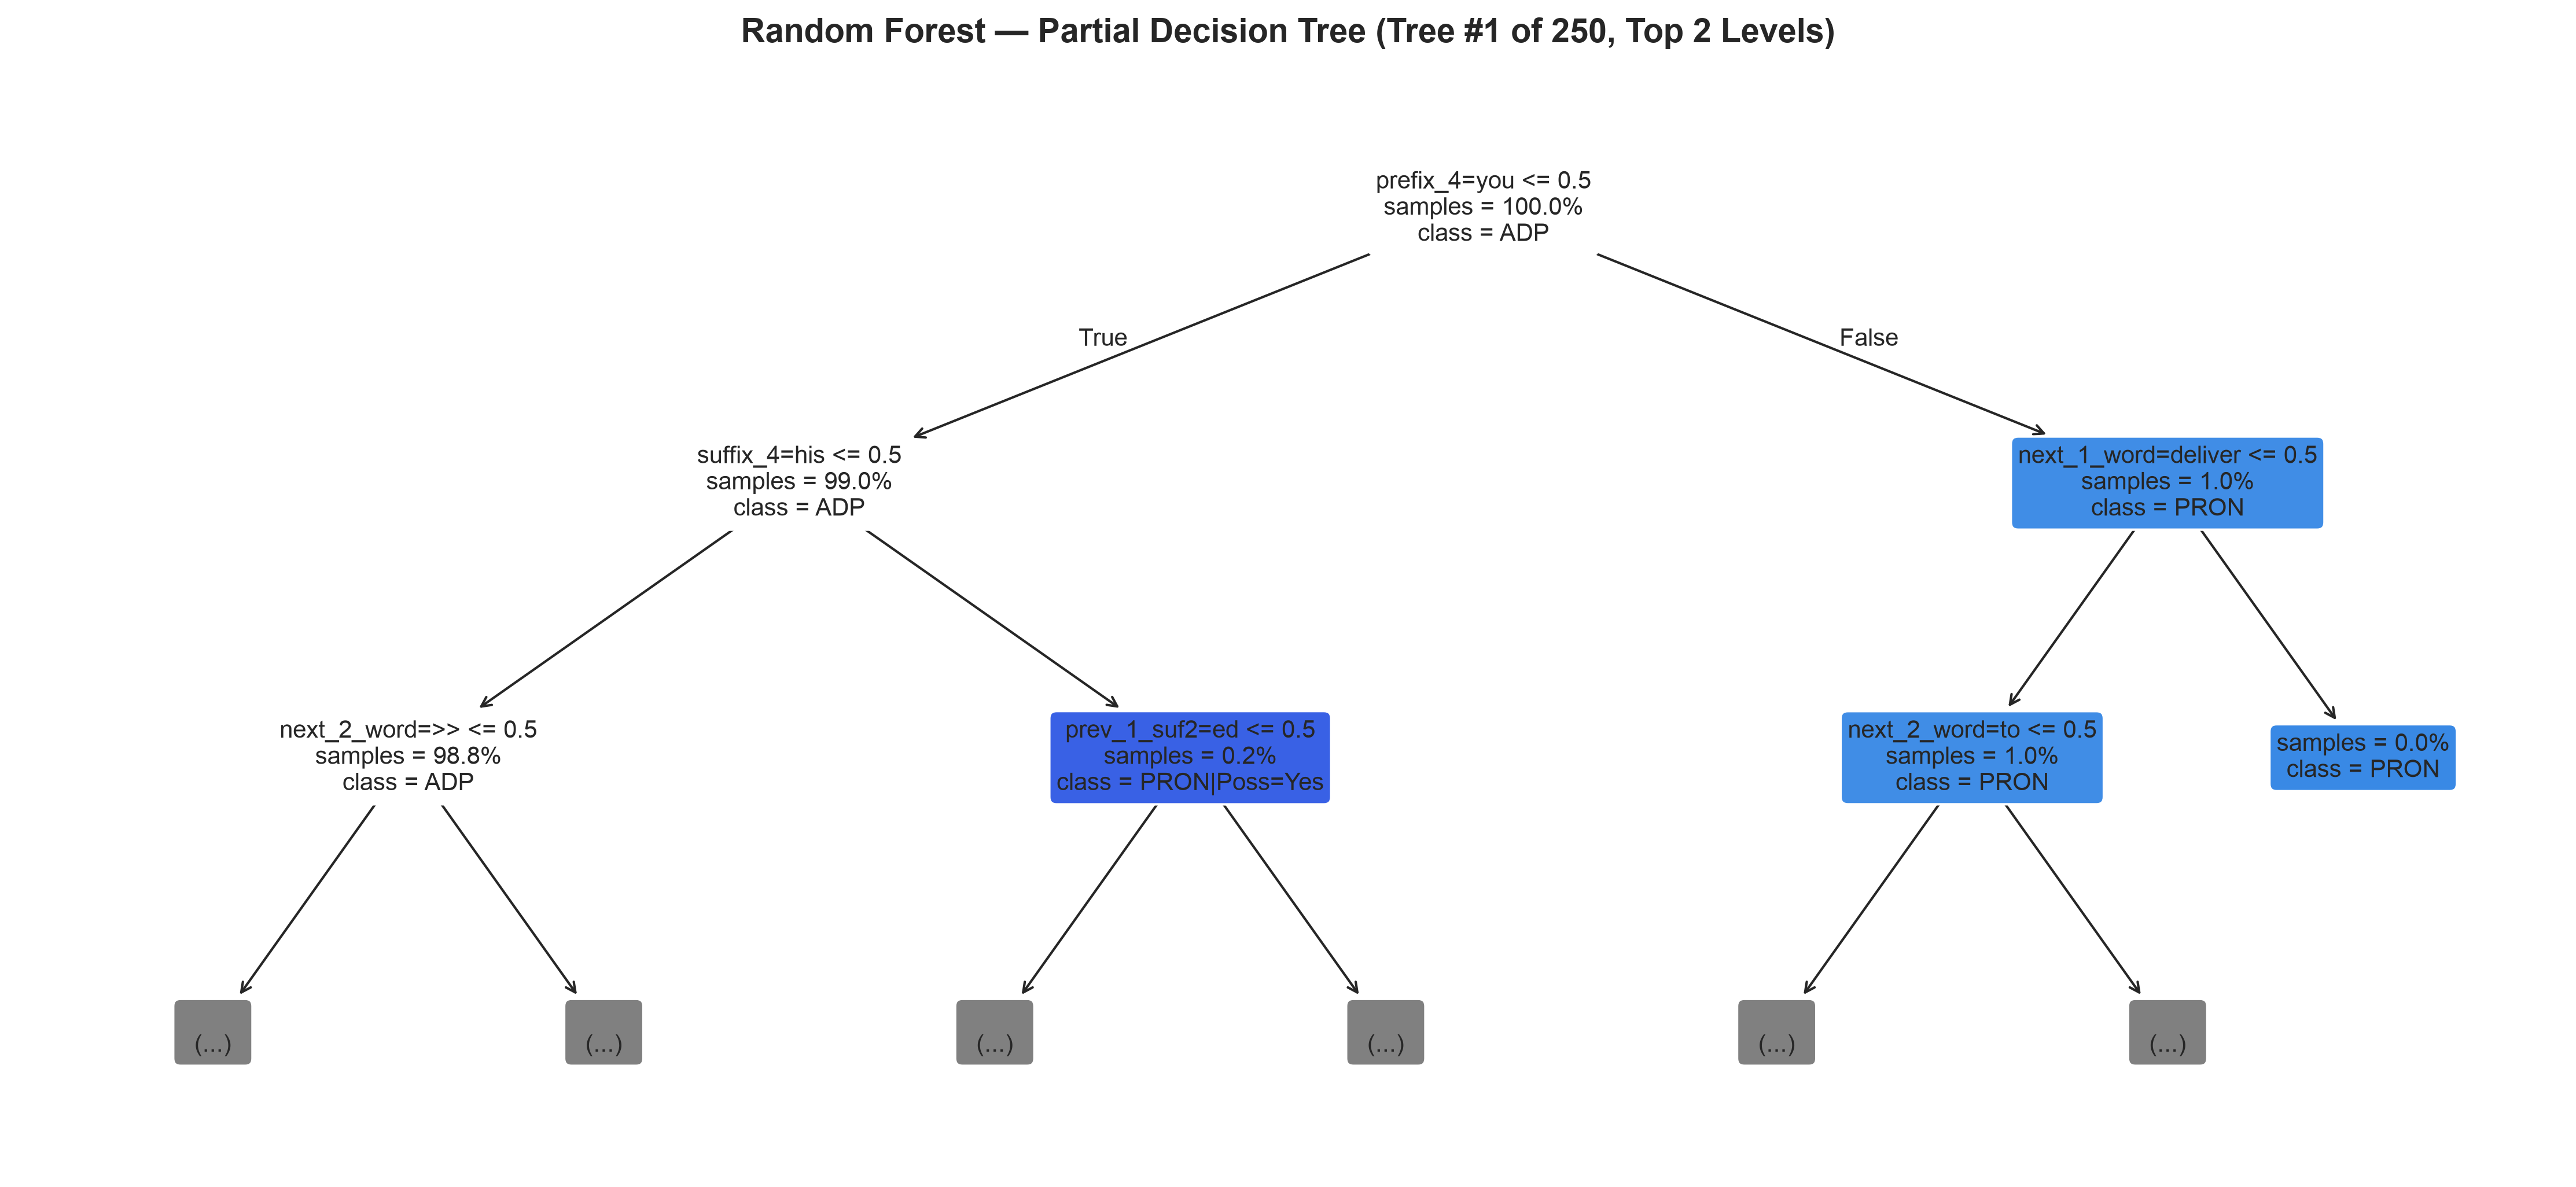

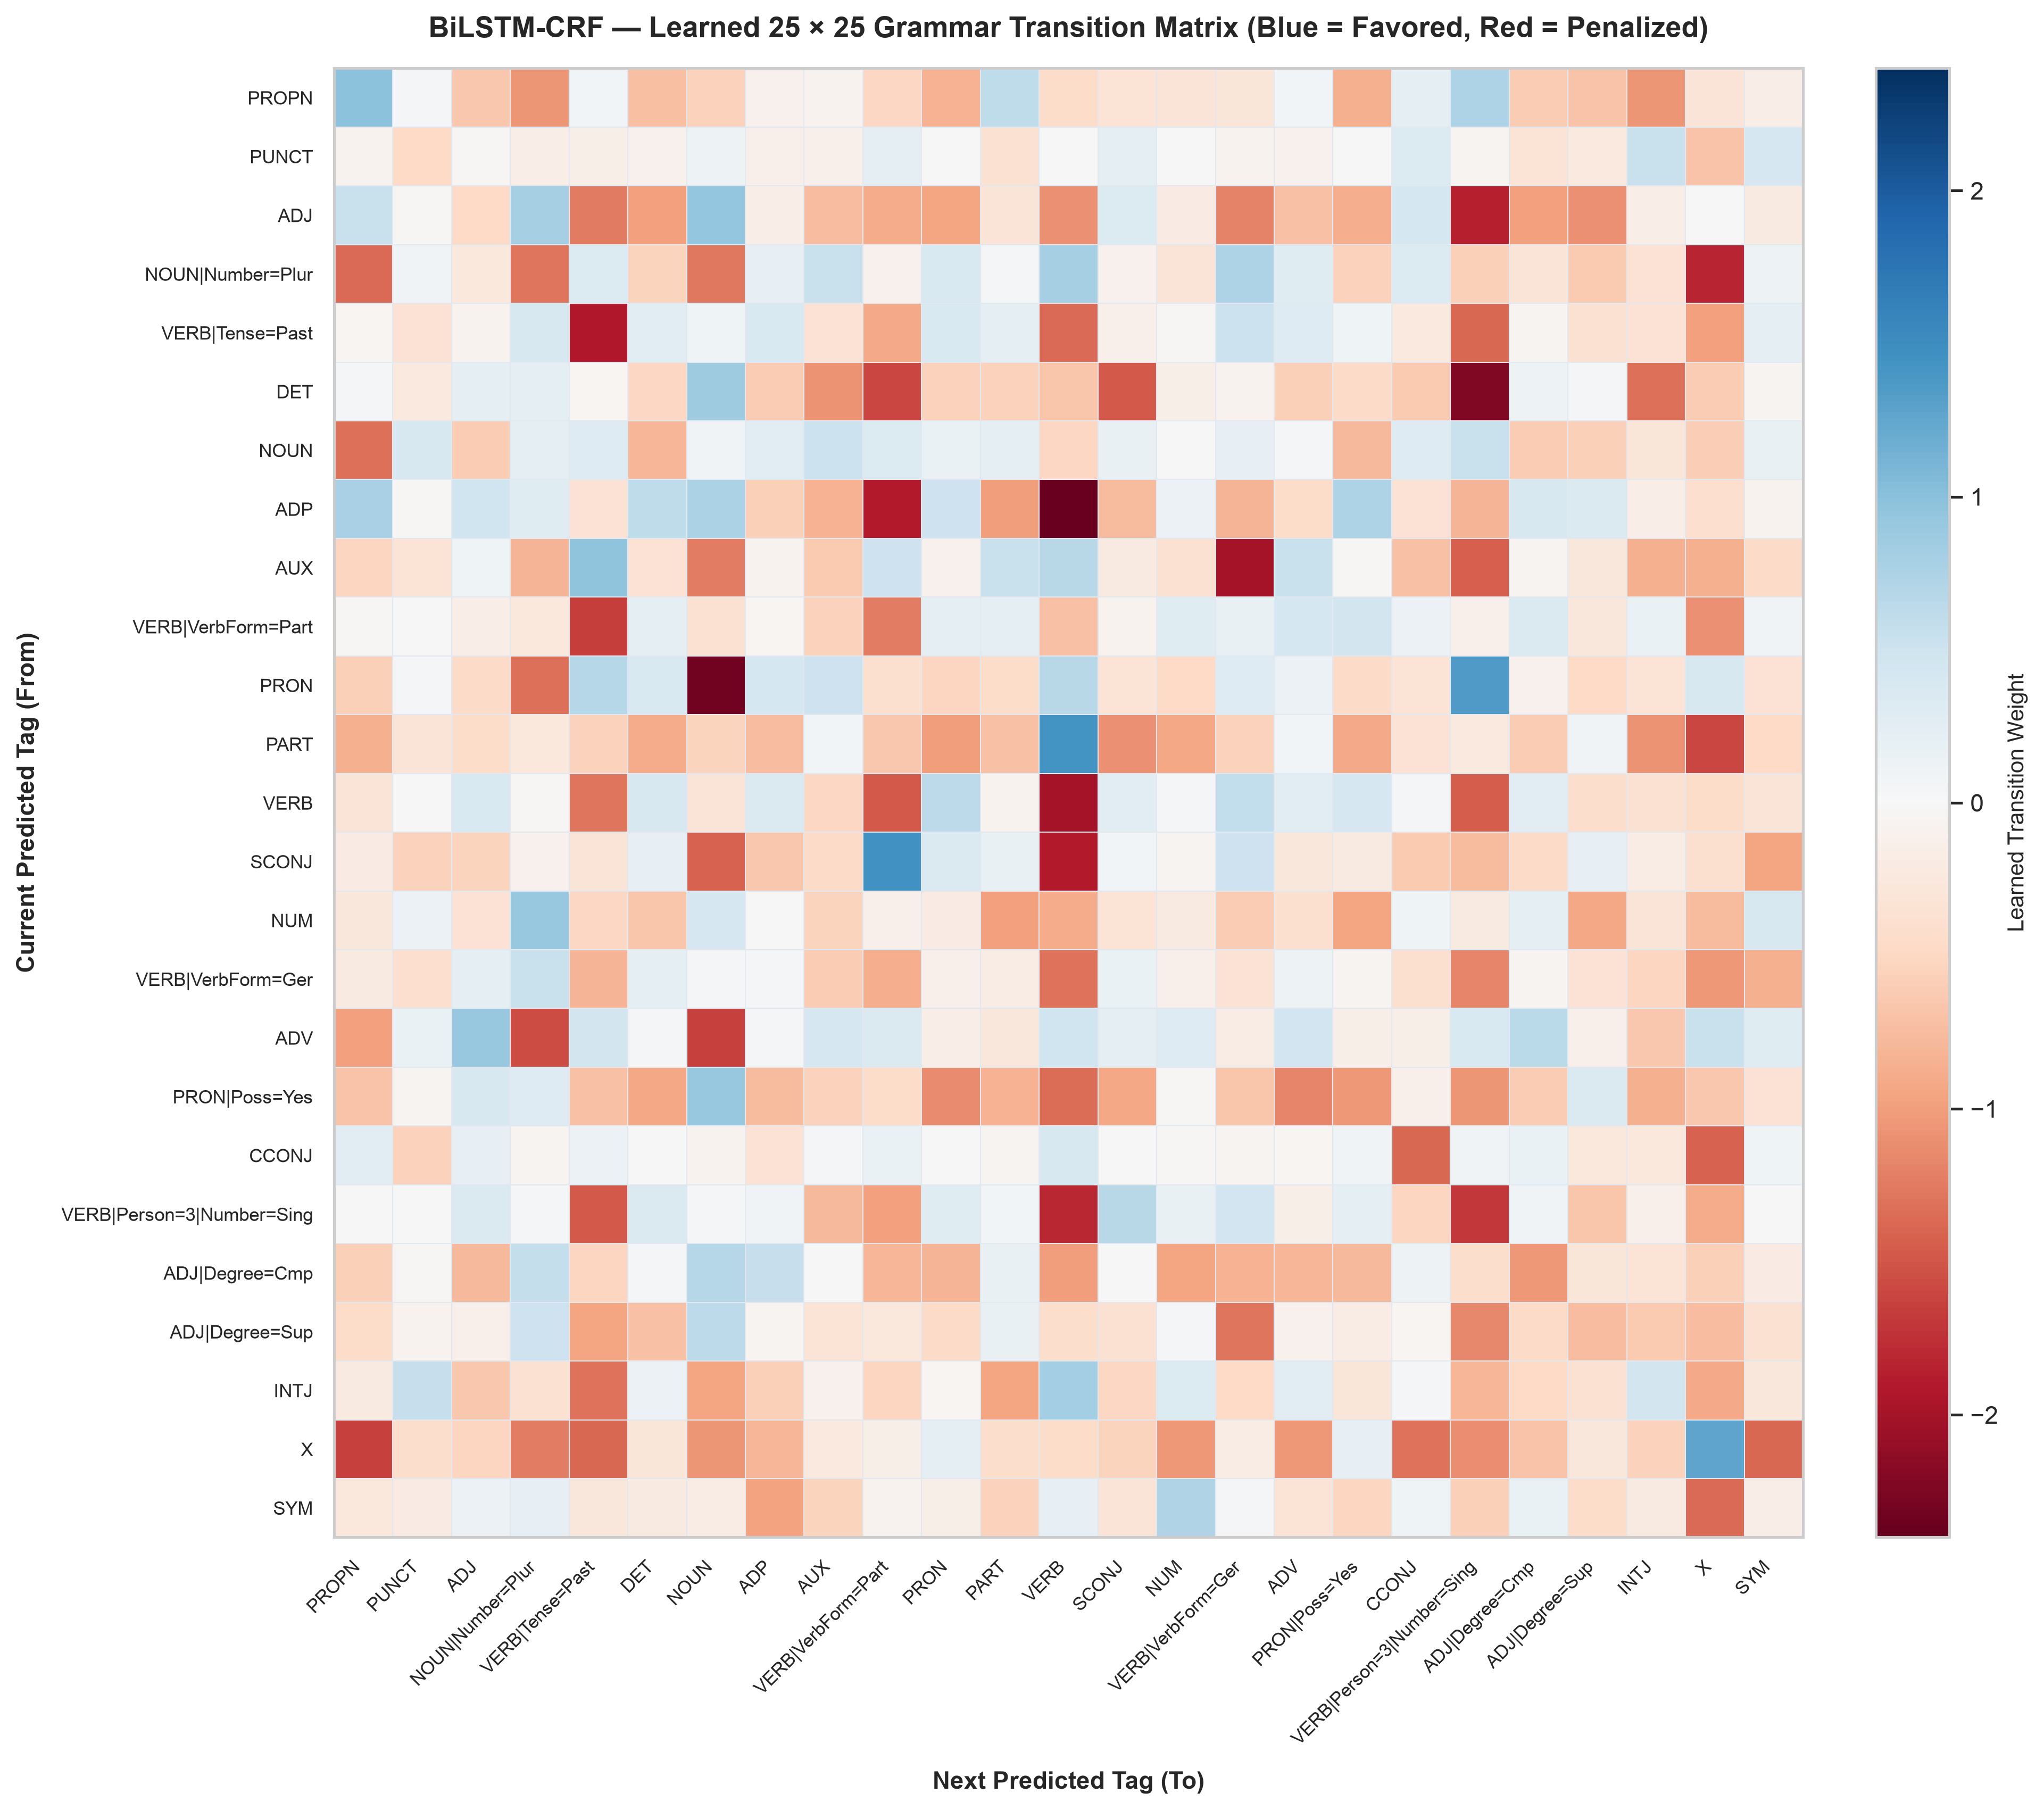

In [47]:
import importlib
import src.visualizations

importlib.reload(src.visualizations)
src.visualizations.export_rf_tree_visual()
src.visualizations.export_crf_transitions_visual()